In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

processed = r'C:\Users\sahil\projects\boston-mbta-ridership\data\processed'
figures   = r'C:\Users\sahil\projects\boston-mbta-ridership\figures'


route_year = pd.read_csv(processed + r'\ridership_route_year.csv', dtype={'route_id': str})

# Dropping Silve (Airport) line because it is irrelevant to our analysis
silver_line = ['741', '742', '743', '746', '749', '751']
route_year = route_year[route_year['route_id'].isin(silver_line) == False]

print(route_year)

     route_id  year  day_type  fare_free  avg_daily_boardings
0           1  2016  saturday      False              8526.00
1           1  2016    sunday      False              5732.30
2           1  2016   weekday      False             11416.30
3           1  2017  saturday      False              9585.50
4           1  2017    sunday      False              6646.30
...       ...   ...       ...        ...                  ...
3816       99  2024    sunday      False               347.40
3817       99  2024   weekday      False               711.10
3818       99  2025  saturday      False               453.00
3819       99  2025    sunday      False               333.40
3820       99  2025   weekday      False               731.58

[3647 rows x 5 columns]


In [16]:
YEAR = 2016  # change this and re-run
DAY_TYPE = "weekday"

subset = route_year[(route_year["day_type"] == DAY_TYPE) & (route_year["route_id"] == '29')]
subset = subset.sort_values("year", ascending = False)
print(subset)


     route_id  year day_type  fare_free  avg_daily_boardings
1453       29  2025  weekday       True           1254.02288
1451       29  2024  weekday       True           1219.50000
1449       29  2023  weekday       True           1364.10000
1447       29  2022  weekday       True           1620.50000
1445       29  2021  weekday       True           1097.30000
1443       29  2020  weekday       True            849.60000
1441       29  2019  weekday       True           2121.00000
1439       29  2018  weekday       True           2042.50000
1437       29  2017  weekday       True           2253.90000
1435       29  2016  weekday       True           2119.40000


In [17]:
# Weekdays only
weekday = route_year[route_year['day_type'] == 'weekday']

# Each route's average weekday boardings across all years
route_avg = weekday.groupby(['route_id', 'fare_free'], as_index=False)['avg_daily_boardings'].mean()

# Comparison routes: other routes averaging more than 1,000 across all years
comparison_routes = route_avg[(route_avg['fare_free'] == False) &
                              (route_avg['avg_daily_boardings'] > 1000)]['route_id']

# Study routes: fare-free routes + comparison routes, all years
study_routes = weekday[(weekday['fare_free']) | (weekday['route_id'].isin(comparison_routes))]

print(len(comparison_routes), 'comparison routes + 3 fare-free routes')
print(study_routes.shape)
study_routes.head()

91 comparison routes + 3 fare-free routes
(898, 5)


,route_id,year,day_type,fare_free,avg_daily_boardings
2,1,2016,weekday,False,11416.3
5,1,2017,weekday,False,11925.0
8,1,2018,weekday,False,11831.4
11,1,2019,weekday,False,14257.0
14,1,2020,weekday,False,5562.7


In [18]:
# Lowest weekday ridership each route had in any year, and how many years it appears
route_check = weekday.groupby(['route_id', 'fare_free'], as_index=False).agg(
    min_boardings=('avg_daily_boardings', 'min'),
    years_present=('year', 'nunique'))

# Above 2,000 in every year: lowest year is over 2,000, and present in all 10 years
above_2000 = route_check[(route_check['min_boardings'] > 2000) &
                         (route_check['years_present'] == 10)]

above_2000 = above_2000.sort_values('min_boardings', ascending=False)
print(len(above_2000), 'routes')
above_2000

19 routes


,route_id,fare_free,min_boardings,years_present
62,28,True,6370.1,10
12,111,False,6357.7,10
131,66,False,5817.6,10
0,1,False,5562.7,10
53,23,True,5544.8,10
80,39,False,4881.4,10
66,32,False,4205.9,10
47,22,False,4155.0,10
123,57,False,3835.2,10
15,116,False,3756.1,10


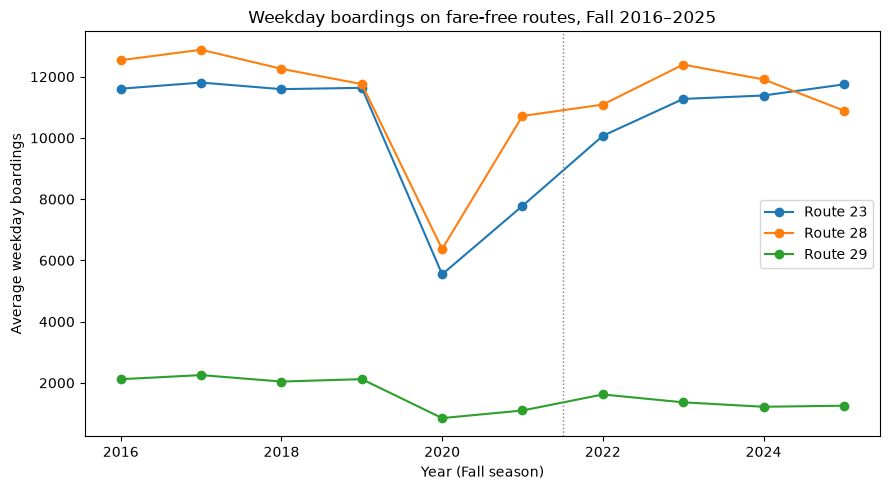

In [ ]:
fare_free = weekday[weekday['route_id'].isin(['23', '28', '29'])]

fig, ax = plt.subplots(figsize=(9, 5))

for route in ['23', '28', '29']:
    d = fare_free[fare_free['route_id'] == route].sort_values('year')
    ax.plot(d['year'], d['avg_daily_boardings'], marker='o', label='Route ' + route)

ax.axvline(2021.5, color='gray', linestyle=':', linewidth=1)    # all three fare-free from 2022
ax.set_title('Weekday boardings on fare-free routes, Fall 2016–2025')
ax.set_xlabel('Year (Fall season)')
ax.set_ylabel('Average weekday boardings')
ax.legend()

plt.tight_layout()
plt.show()

Top 5 other routes: ['66', '1', '111', '39', '57']


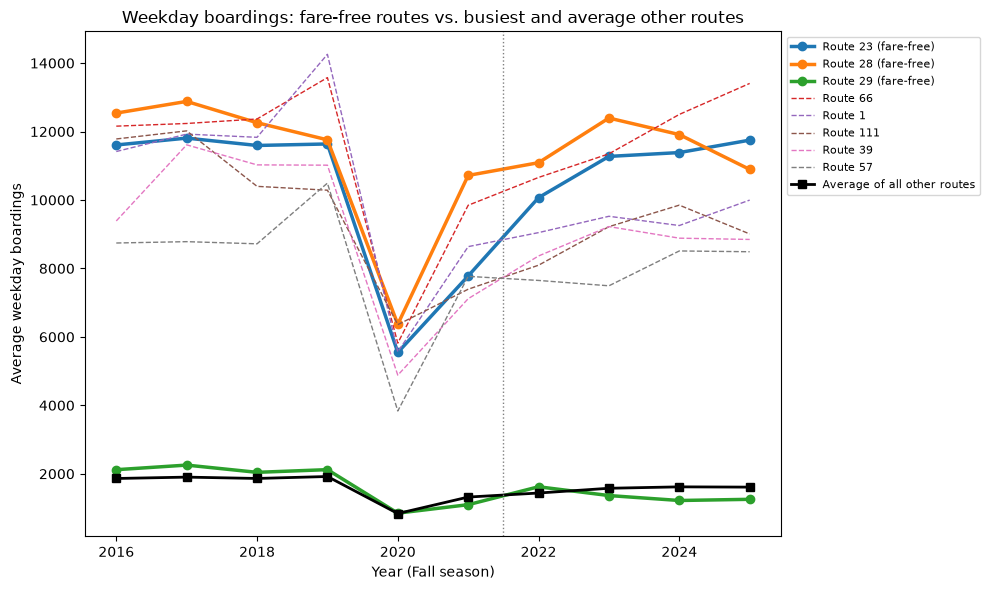

In [20]:
fare_free_ids = ['23', '28', '29']

# ---- Top 5 other routes, by average weekday ridership across all years ----
others = weekday[weekday['fare_free'] == False]
top5_ids = (others.groupby('route_id')['avg_daily_boardings'].mean()
                  .sort_values(ascending=False)
                  .head(5)
                  .index.tolist())
print('Top 5 other routes:', top5_ids)

# ---- Average of all remaining routes (not fare-free, not top 5) ----
rest = others[others['route_id'].isin(top5_ids) == False]
rest_avg = rest.groupby('year', as_index=False)['avg_daily_boardings'].mean()

# ---- Plot ----
fig, ax = plt.subplots(figsize=(10, 6))

# Fare-free routes: solid, thick
for route in fare_free_ids:
    d = weekday[weekday['route_id'] == route].sort_values('year')
    ax.plot(d['year'], d['avg_daily_boardings'], marker='o', linewidth=2.5, label='Route ' + route + ' (fare-free)')

# Top 5 other routes: thin, dashed
for route in top5_ids:
    d = weekday[weekday['route_id'] == route].sort_values('year')
    ax.plot(d['year'], d['avg_daily_boardings'], linestyle='--', linewidth=1, label='Route ' + route)

# Average of all remaining routes: black
ax.plot(rest_avg['year'], rest_avg['avg_daily_boardings'], color='black', linewidth=2,
        marker='s', label='Average of all other routes')

ax.axvline(2021.5, color='gray', linestyle=':', linewidth=1)    # all three fare-free from 2022
ax.set_title('Weekday boardings: fare-free routes vs. busiest and average other routes')
ax.set_xlabel('Year (Fall season)')
ax.set_ylabel('Average weekday boardings')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))    # legend outside the chart

plt.tight_layout()
plt.show()

Top 10 other routes: ['66', '1', '111', '39', '57', '32', '22', '116', '16', '77']


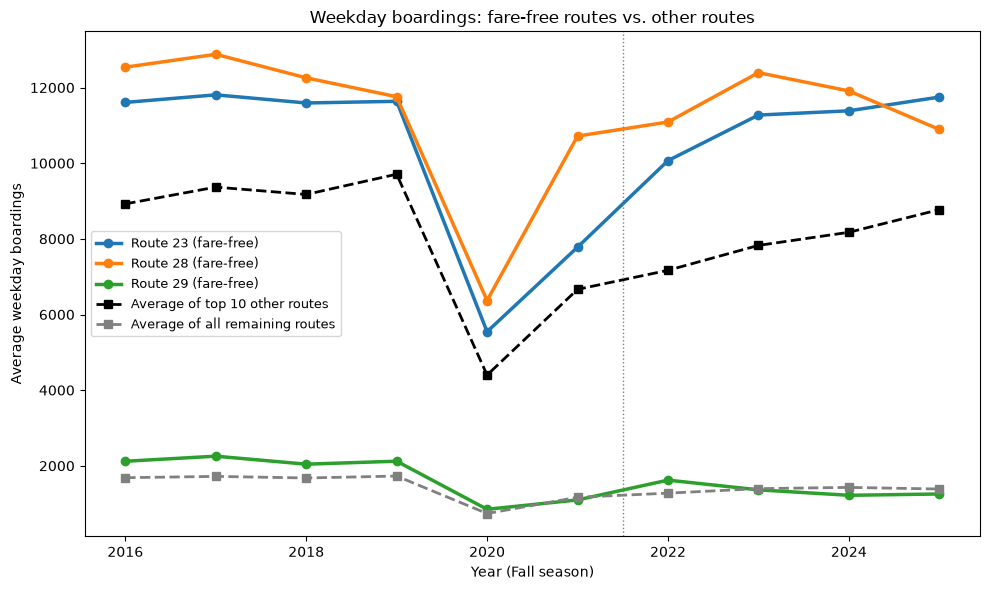

In [21]:
fare_free_ids = ['23', '28', '29']

# ---- Top 10 other routes, by average weekday ridership across all years ----
others = weekday[weekday['fare_free'] == False]
top10_ids = (others.groupby('route_id')['avg_daily_boardings'].mean()
                   .sort_values(ascending=False)
                   .head(10)
                   .index.tolist())
print('Top 10 other routes:', top10_ids)

# ---- Average per year: top 10, and all remaining routes ----
top10_avg = (others[others['route_id'].isin(top10_ids)]
             .groupby('year', as_index=False)['avg_daily_boardings'].mean())

rest_avg = (others[others['route_id'].isin(top10_ids) == False]
            .groupby('year', as_index=False)['avg_daily_boardings'].mean())

# ---- Plot ----
fig, ax = plt.subplots(figsize=(10, 6))

# Fare-free routes, each on its own
for route in fare_free_ids:
    d = weekday[weekday['route_id'] == route].sort_values('year')
    ax.plot(d['year'], d['avg_daily_boardings'], marker='o', linewidth=2.5, label='Route ' + route + ' (fare-free)')

# Group averages
ax.plot(top10_avg['year'], top10_avg['avg_daily_boardings'], color='black', linestyle='--',
        linewidth=2, marker='s', label='Average of top 10 other routes')
ax.plot(rest_avg['year'], rest_avg['avg_daily_boardings'], color='gray', linestyle='--',
        linewidth=2, marker='s', label='Average of all remaining routes')

ax.axvline(2021.5, color='gray', linestyle=':', linewidth=1)    # all three fare-free from 2022
ax.set_title('Weekday boardings: fare-free routes vs. other routes')
ax.set_xlabel('Year (Fall season)')
ax.set_ylabel('Average weekday boardings')
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [22]:
# Index each line to its own 2019 value (2019 = 100)
indexed = summary / summary.loc[2019] * 100

ax = indexed.plot(figsize=(10, 6), marker='o')
ax.axhline(100, color='gray', linestyle='--', linewidth=1)
ax.axvline(2021.5, color='gray', linestyle=':', linewidth=1)
ax.set_title('Weekday boardings, indexed to Fall 2019 = 100')
ax.set_xlabel('Year (Fall season)')
ax.set_ylabel('Index (2019 = 100)')

plt.tight_layout()
plt.savefig(figures + r'\fare_free_vs_groups_indexed.png', dpi=200)
plt.show()

NameError: name 'summary' is not defined

In [28]:
fare_free_ids = ['23', '28', '29']
others = weekday[weekday['fare_free'] == False]

# ---- Top 10 other routes, chosen by 2019 weekday ridership ----
top10_ids = (others[others['year'] == 2019]
             .sort_values('avg_daily_boardings', ascending=False)
             .head(10)['route_id'].tolist())
print('Top 10 other routes:', top10_ids)

# ---- Averages per year ----
top10_avg = (others[others['route_id'].isin(top10_ids)]
             .groupby('year')['avg_daily_boardings'].mean())

rest_avg = (others[others['route_id'].isin(top10_ids) == False]
            .groupby('year')['avg_daily_boardings'].mean())

# ---- Summary table: one column per line in the chart ----
summary = pd.DataFrame({
    'Route 23':   weekday[weekday['route_id'] == '23'].set_index('year')['avg_daily_boardings'],
    'Route 28':   weekday[weekday['route_id'] == '28'].set_index('year')['avg_daily_boardings'],
    'Route 29':   weekday[weekday['route_id'] == '29'].set_index('year')['avg_daily_boardings'],
    'Top 10 avg': top10_avg,
    'Rest avg':   rest_avg,
}).round(0)

summary

Top 10 other routes: ['1', '66', '39', '57', '111', '32', '22', '9', '77', '116']


,Route 23,Route 28,Route 29,Top 10 avg,Rest avg
year,,,,,
2016,11608.0,12539.0,2119.0,8980.0,1681.0
2017,11808.0,12880.0,2254.0,9458.0,1714.0
2018,11593.0,12258.0,2042.0,9282.0,1670.0
2019,11637.0,11758.0,2121.0,9803.0,1722.0
2020,5545.0,6370.0,850.0,4283.0,746.0
2021,7780.0,10718.0,1097.0,6496.0,1181.0
2022,10068.0,11090.0,1620.0,7018.0,1288.0
2023,11273.0,12394.0,1364.0,7714.0,1404.0
2024,11386.0,11911.0,1220.0,8021.0,1440.0


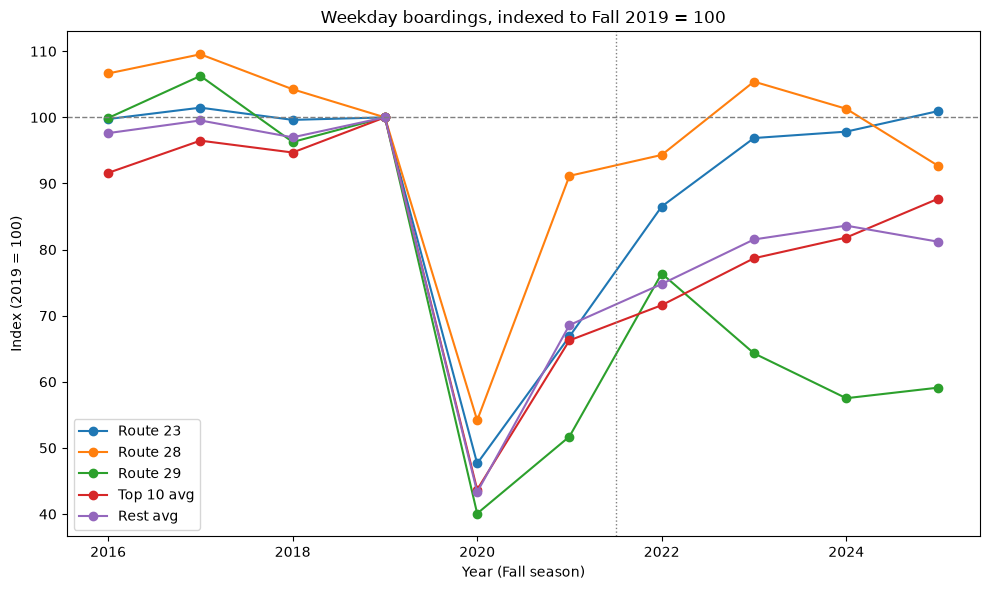

In [29]:
# Index each column to its own 2019 value (2019 = 100)
indexed = summary / summary.loc[2019] * 100

ax = indexed.plot(figsize=(10, 6), marker='o')
ax.axhline(100, color='gray', linestyle='--', linewidth=1)       # 2019 level
ax.axvline(2021.5, color='gray', linestyle=':', linewidth=1)     # all three fare-free from 2022
ax.set_title('Weekday boardings, indexed to Fall 2019 = 100')
ax.set_xlabel('Year (Fall season)')
ax.set_ylabel('Index (2019 = 100)')

plt.tight_layout()
plt.savefig(figures + r'\fare_free_vs_groups_indexed.png', dpi=200)
plt.show()

In [30]:
fare_free_ids = ['23', '28', '29']
others = weekday[weekday['fare_free'] == False]

# ---- Top 8 other routes, chosen by 2019 weekday ridership ----
top8_ids = (others[others['year'] == 2019]
            .sort_values('avg_daily_boardings', ascending=False)
            .head(8)['route_id'].tolist())
print('Top 8 other routes:', top8_ids)

# ---- Averages per year ----
top8_avg = (others[others['route_id'].isin(top8_ids)]
            .groupby('year')['avg_daily_boardings'].mean())

rest_avg = (others[others['route_id'].isin(top8_ids) == False]
            .groupby('year')['avg_daily_boardings'].mean())

# ---- Summary table: one column per line in the chart ----
summary = pd.DataFrame({
    'Route 23':  weekday[weekday['route_id'] == '23'].set_index('year')['avg_daily_boardings'],
    'Route 28':  weekday[weekday['route_id'] == '28'].set_index('year')['avg_daily_boardings'],
    'Route 29':  weekday[weekday['route_id'] == '29'].set_index('year')['avg_daily_boardings'],
    'Top 8 avg': top8_avg,
    'Rest avg':  rest_avg,
}).round(0)

summary

Top 8 other routes: ['1', '66', '39', '57', '111', '32', '22', '9']


,Route 23,Route 28,Route 29,Top 8 avg,Rest avg
year,,,,,
2016,11608.0,12539.0,2119.0,9606.0,1745.0
2017,11808.0,12880.0,2254.0,10192.0,1777.0
2018,11593.0,12258.0,2042.0,9935.0,1736.0
2019,11637.0,11758.0,2121.0,10616.0,1788.0
2020,5545.0,6370.0,850.0,4565.0,782.0
2021,7780.0,10718.0,1097.0,7002.0,1232.0
2022,10068.0,11090.0,1620.0,7557.0,1343.0
2023,11273.0,12394.0,1364.0,8266.0,1466.0
2024,11386.0,11911.0,1220.0,8584.0,1506.0


In [33]:
# % change from 2020 (2020 = 0)
pct_change = ((summary / summary.loc[2020] - 1) * 100).round(1)

pct_change

,Route 23,Route 28,Route 29,Top 8 avg,Rest avg
year,,,,,
2016,109.3,96.8,149.3,110.4,123.1
2017,112.9,102.2,165.2,123.3,127.2
2018,109.1,92.4,140.2,117.6,122.0
2019,109.9,84.6,149.5,132.6,128.6
2020,0.0,0.0,0.0,0.0,0.0
2021,40.3,68.3,29.1,53.4,57.5
2022,81.6,74.1,90.6,65.5,71.7
2023,103.3,94.6,60.5,81.1,87.5
2024,105.3,87.0,43.5,88.0,92.6


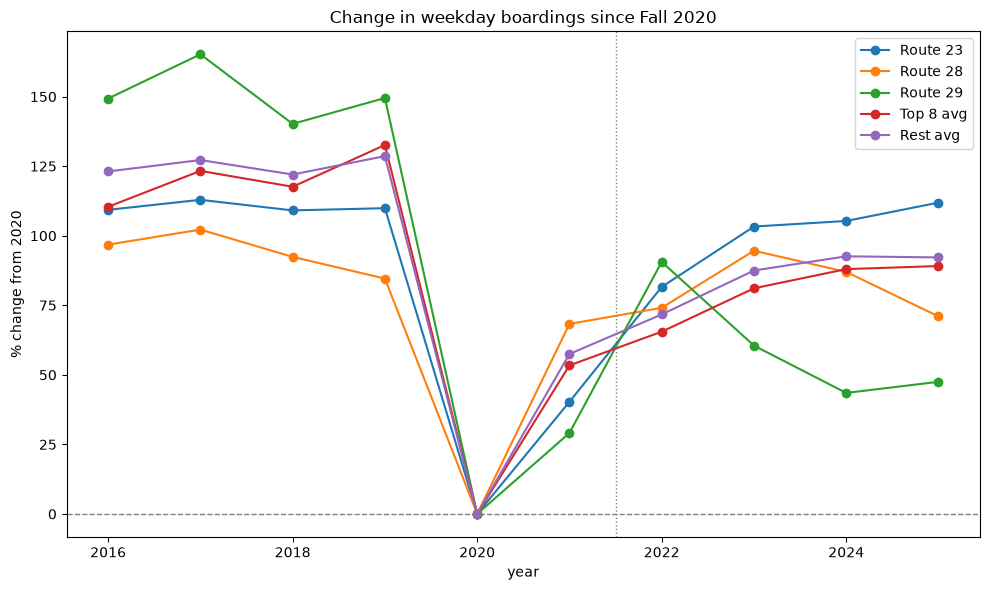

In [35]:
ax = pct_change.plot(figsize=(10, 6), marker='o')
       # 2019 level
ax.axvline(2021.5, color='gray', linestyle=':', linewidth=1)     # all three fare-free from 2022
ax.set_title('Change in weekday boardings since Fall 2019')
ax.axhline(0, color='gray', linestyle='--', linewidth=1)         # 2020 level
ax.set_title('Change in weekday boardings since Fall 2020')
ax.set_ylabel('% change from 2020')
plt.tight_layout()
plt.show()

In [36]:
import matplotlib.ticker as mticker

# Same color for each line in every chart
colors = {
    'Route 23':  '#D55E00',   # dark orange
    'Route 28':  '#E69F00',   # orange
    'Route 29':  '#CC79A7',   # pink
    'Top 8 avg': '#0072B2',   # blue
    'Rest avg':  '#7F7F7F',   # gray
}

# Readable names for legends and bars
labels = {
    'Route 23':  'Route 23 (fare-free)',
    'Route 28':  'Route 28 (fare-free)',
    'Route 29':  'Route 29 (fare-free)',
    'Top 8 avg': 'Average of top 8 other routes',
    'Rest avg':  'Average of all remaining routes',
}

def add_program_markers(ax):
    """Shade the COVID year and mark when each route became fare-free."""
    bottom, top = ax.get_ylim()
    ax.axvspan(2019.5, 2020.5, color='lightgray', alpha=0.4)                 # COVID year
    ax.text(2020, bottom, 'COVID', ha='center', va='bottom', fontsize=9, color='dimgray')
    ax.axvline(2020.8, color='black', linestyle=':', linewidth=1)            # Route 28: Aug 2021
    ax.text(2020.75, top, 'Route 28\nfare-free\n(Aug 2021)', ha='right', va='top', fontsize=8)
    ax.axvline(2021.5, color='black', linestyle=':', linewidth=1)            # Routes 23 & 29: Mar 2022
    ax.text(2021.55, top, 'Routes 23 & 29\nfare-free\n(Mar 2022)', ha='left', va='top', fontsize=8)

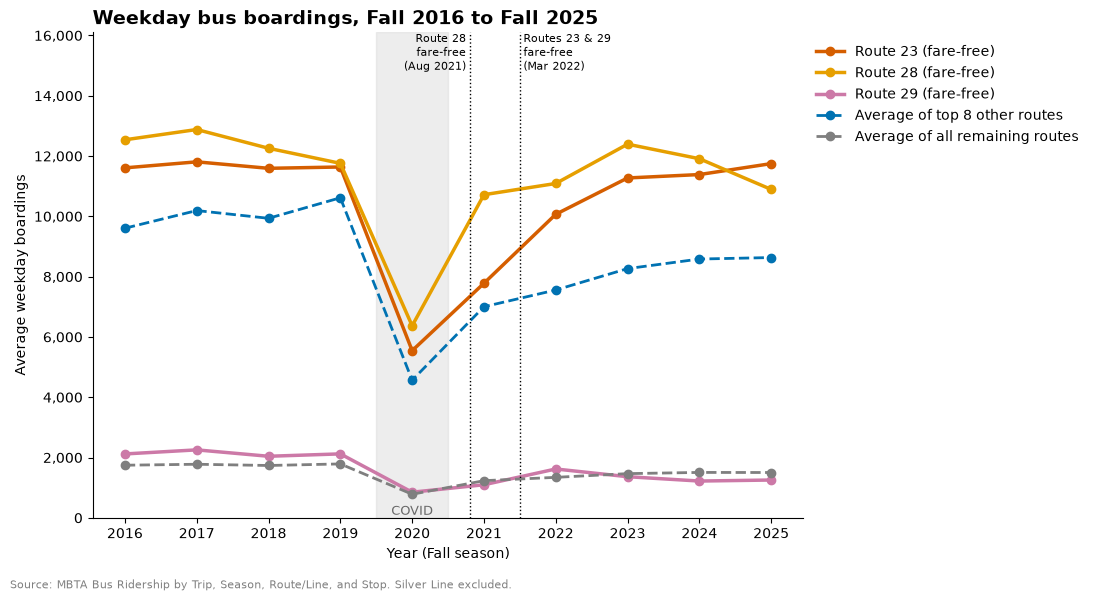

In [37]:
fig, ax = plt.subplots(figsize=(11, 6))

for col in summary.columns:
    is_route = 'Route' in col                                 # fare-free routes: solid; averages: dashed
    ax.plot(summary.index, summary[col], marker='o',
            linewidth=2.5 if is_route else 2,
            linestyle='-' if is_route else '--',
            color=colors[col], label=labels[col])

ax.set_ylim(0, summary.max().max() * 1.25)                   # room at the top for labels
add_program_markers(ax)

ax.set_title('Weekday bus boardings, Fall 2016 to Fall 2025', fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Year (Fall season)')
ax.set_ylabel('Average weekday boardings')
ax.set_xticks(summary.index)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))   # 12,000 instead of 12000
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False)

fig.text(0.01, 0.01, 'Source: MBTA Bus Ridership by Trip, Season, Route/Line, and Stop. Silver Line excluded.',
         fontsize=8, color='gray')
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(figures + r'\chart1_weekday_boardings.png', dpi=200, bbox_inches='tight')
plt.show()

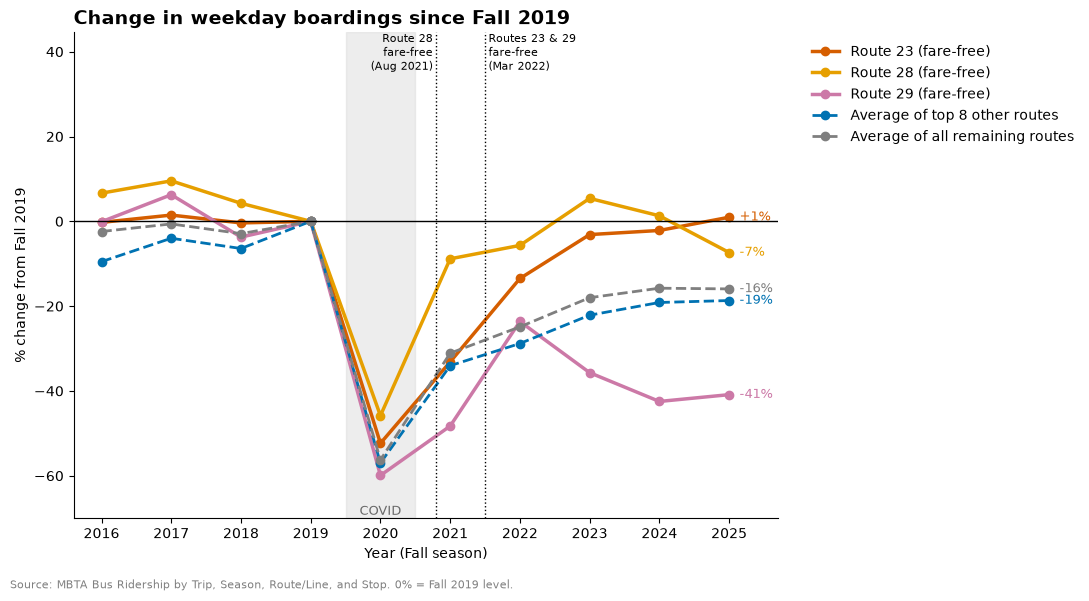

In [38]:
pct_change = (summary / summary.loc[2019] - 1) * 100

fig, ax = plt.subplots(figsize=(11, 6))

for col in pct_change.columns:
    is_route = 'Route' in col
    ax.plot(pct_change.index, pct_change[col], marker='o',
            linewidth=2.5 if is_route else 2,
            linestyle='-' if is_route else '--',
            color=colors[col], label=labels[col])

    # Label the 2025 value at the end of each line
    last = pct_change[col].iloc[-1]
    ax.text(2025.15, last, f'{last:+.0f}%', va='center', fontsize=9, color=colors[col])

ax.axhline(0, color='black', linewidth=1)                    # 0% = 2019 level
ax.set_ylim(pct_change.min().min() - 10, pct_change.max().max() + 35)
add_program_markers(ax)

ax.set_title('Change in weekday boardings since Fall 2019', fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Year (Fall season)')
ax.set_ylabel('% change from Fall 2019')
ax.set_xticks(pct_change.index)
ax.set_xlim(2015.6, 2025.7)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', bbox_to_anchor=(1.03, 1), frameon=False)

fig.text(0.01, 0.01, 'Source: MBTA Bus Ridership by Trip, Season, Route/Line, and Stop. 0% = Fall 2019 level.',
         fontsize=8, color='gray')
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(figures + r'\chart2_pct_change.png', dpi=200, bbox_inches='tight')
plt.show()

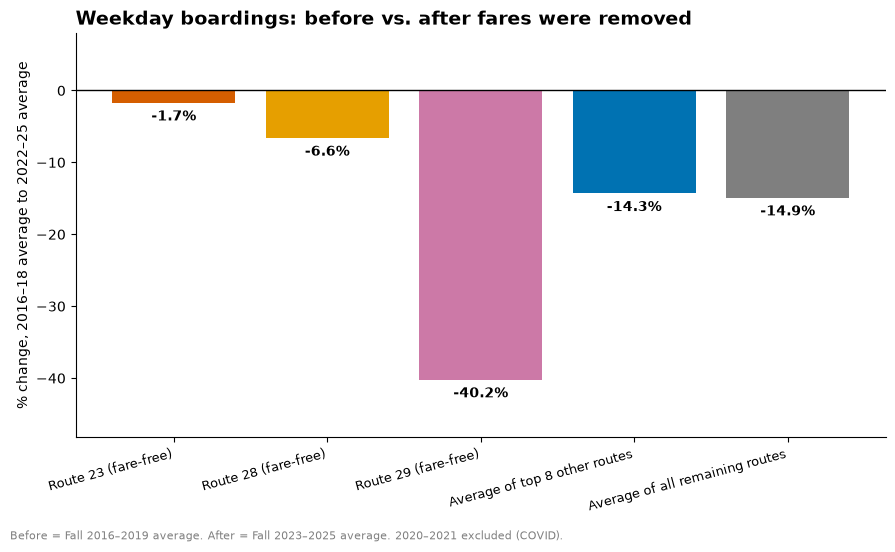

Route 23     -1.7
Route 28     -6.6
Route 29    -40.2
Top 8 avg   -14.3
Rest avg    -14.9
dtype: float64

In [43]:
# Average weekday boardings before (2016-2019) and after (2022-2025); COVID years skipped
before = summary.loc[2016:2018].mean()
after  = summary.loc[2023:2025].mean()
growth = ((after / before - 1) * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar([labels[c] for c in growth.index], growth.values,
              color=[colors[c] for c in growth.index])

# Write the value on each bar
for bar, value in zip(bars, growth.values):
    ax.text(bar.get_x() + bar.get_width() / 2,
            value + (1 if value >= 0 else -1),
            f'{value:+.1f}%',
            ha='center', va='bottom' if value >= 0 else 'top',
            fontsize=10, fontweight='bold')

ax.axhline(0, color='black', linewidth=1)
ax.set_ylim(min(growth.min(), 0) - 8, max(growth.max(), 0) + 8)

ax.set_title('Weekday boardings: before vs. after fares were removed', fontsize=14, fontweight='bold', loc='left')
ax.set_ylabel('% change, 2016–18 average to 2022–25 average')
plt.setp(ax.get_xticklabels(), rotation=15, ha='right', fontsize=9)
ax.spines[['top', 'right']].set_visible(False)

fig.text(0.01, 0.01, 'Before = Fall 2016–2019 average. After = Fall 2023–2025 average. 2020–2021 excluded (COVID).',
         fontsize=8, color='gray')
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(figures + r'\chart3_before_after.png', dpi=200, bbox_inches='tight')
plt.show()

growth

In [44]:
def route_group(route_id):
    """Which line in the charts a route belongs to."""
    if route_id in ['23', '28', '29']:
        return 'Route ' + route_id
    elif route_id in top8_ids:
        return 'Top 8 avg'
    else:
        return 'Rest avg'

route_year['group'] = route_year['route_id'].apply(route_group)
order = ['Route 23', 'Route 28', 'Route 29', 'Top 8 avg', 'Rest avg']

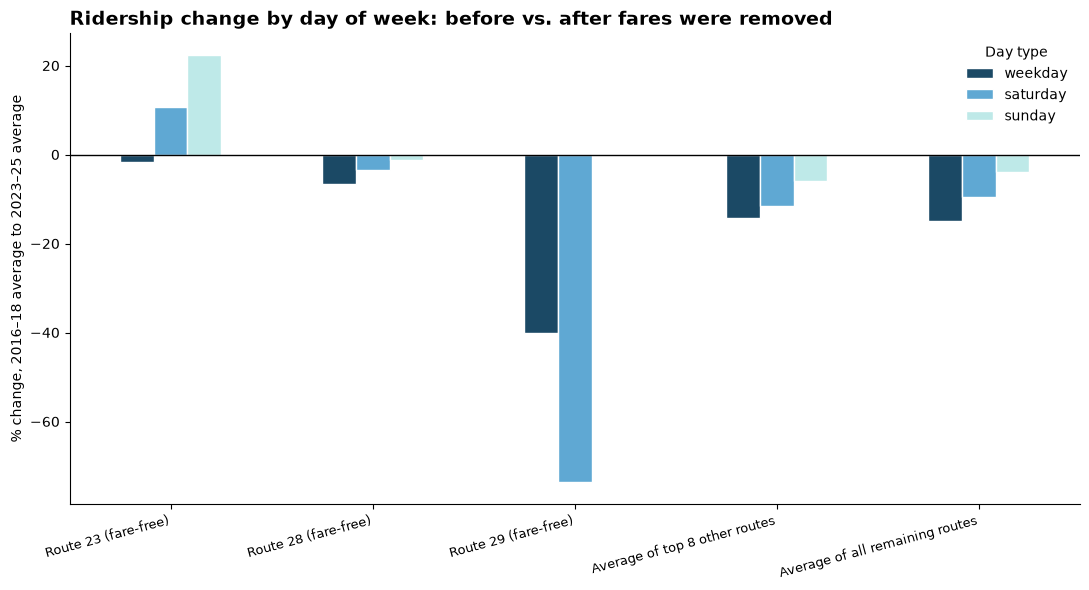

day_type,weekday,saturday,sunday
Route 23 (fare-free),-1.7,10.8,22.5
Route 28 (fare-free),-6.6,-3.4,-1.1
Route 29 (fare-free),-40.2,-73.7,NaN
Average of top 8 other routes,-14.3,-11.6,-5.9
Average of all remaining routes,-14.9,-9.6,-3.8


In [47]:
# Average per group, day type and year
by_day = route_year.groupby(['group', 'day_type', 'year'], as_index=False)['avg_daily_boardings'].mean()

before = by_day[by_day['year'].between(2016, 2018)].groupby(['group', 'day_type'])['avg_daily_boardings'].mean()
after  = by_day[by_day['year'].between(2023, 2025)].groupby(['group', 'day_type'])['avg_daily_boardings'].mean()

growth_day = ((after / before - 1) * 100).unstack('day_type')
growth_day = growth_day.loc[order, ['weekday', 'saturday', 'sunday']]
growth_day.index = [labels[g] for g in growth_day.index]

ax = growth_day.plot(kind='bar', figsize=(11, 6), color=['#1b4965', '#5fa8d3', '#bee9e8'], edgecolor='white')
ax.axhline(0, color='black', linewidth=1)
ax.set_title('Ridership change by day of week: before vs. after fares were removed',
             fontsize=14, fontweight='bold', loc='left')
ax.set_ylabel('% change, 2016–18 average to 2023–25 average')
ax.set_xlabel('')
plt.setp(ax.get_xticklabels(), rotation=15, ha='right', fontsize=9)
ax.legend(title='Day type', frameon=False)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(figures + r'\chart4_day_type.png', dpi=200, bbox_inches='tight')
plt.show()

growth_day.round(1)

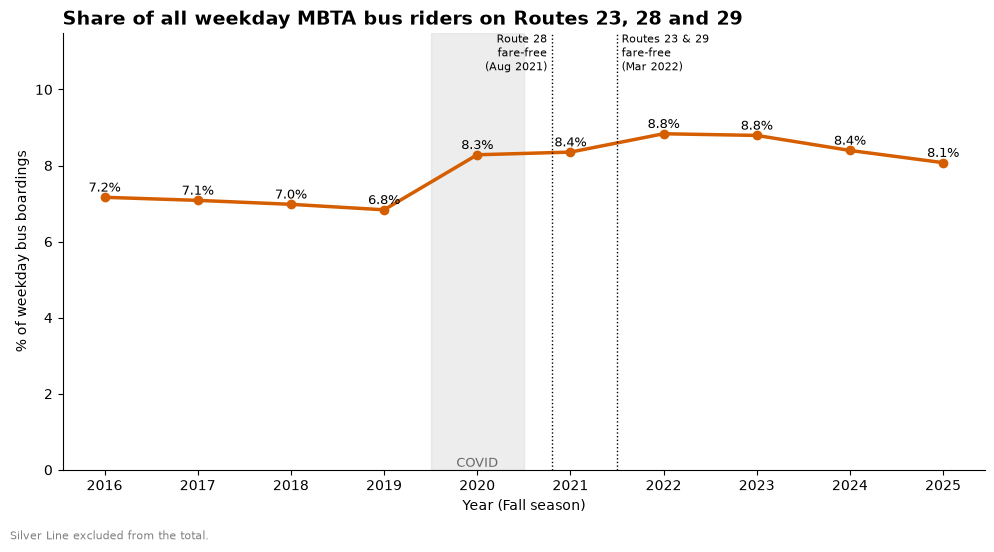

In [48]:
total_riders     = weekday.groupby('year')['avg_daily_boardings'].sum()
fare_free_riders = weekday[weekday['fare_free']].groupby('year')['avg_daily_boardings'].sum()
share = fare_free_riders / total_riders * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(share.index, share.values, marker='o', linewidth=2.5, color='#D55E00')

for year, value in share.items():                         # label each point
    ax.text(year, value + 0.15, f'{value:.1f}%', ha='center', fontsize=9)

ax.set_ylim(0, share.max() * 1.3)
add_program_markers(ax)
ax.set_title('Share of all weekday MBTA bus riders on Routes 23, 28 and 29',
             fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Year (Fall season)')
ax.set_ylabel('% of weekday bus boardings')
ax.set_xticks(share.index)
ax.spines[['top', 'right']].set_visible(False)
fig.text(0.01, 0.01, 'Silver Line excluded from the total.', fontsize=8, color='gray')

plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(figures + r'\chart5_share.png', dpi=200, bbox_inches='tight')
plt.show()

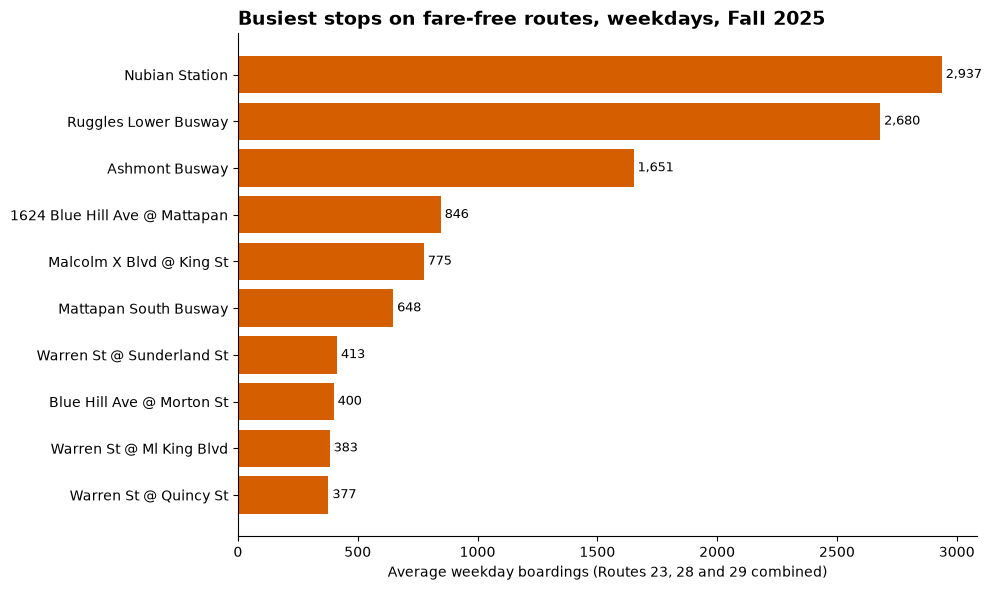

In [49]:
stops = pd.read_csv(processed + r'\ridership_stops_year.csv', dtype={'route_id': str, 'stop_id': str})
ff_stops = stops[(stops['fare_free']) & (stops['day_type'] == 'weekday')]
latest = ff_stops['year'].max()

# Add up all three routes at each stop (some stops serve more than one)
stop_totals = (ff_stops[ff_stops['year'] == latest]
               .groupby('stop_id', as_index=False)
               .agg(stop_name=('stop_name', 'first'), boardings=('boardings', 'sum')))

top_stops = stop_totals.sort_values('boardings', ascending=False).head(10).sort_values('boardings')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_stops['stop_name'].str.title(), top_stops['boardings'], color='#D55E00')

for i, value in enumerate(top_stops['boardings']):
    ax.text(value, i, f' {value:,.0f}', va='center', fontsize=9)

ax.set_title(f'Busiest stops on fare-free routes, weekdays, Fall {latest}', fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Average weekday boardings (Routes 23, 28 and 29 combined)')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(figures + r'\chart6_busiest_stops.png', dpi=200, bbox_inches='tight')
plt.show()

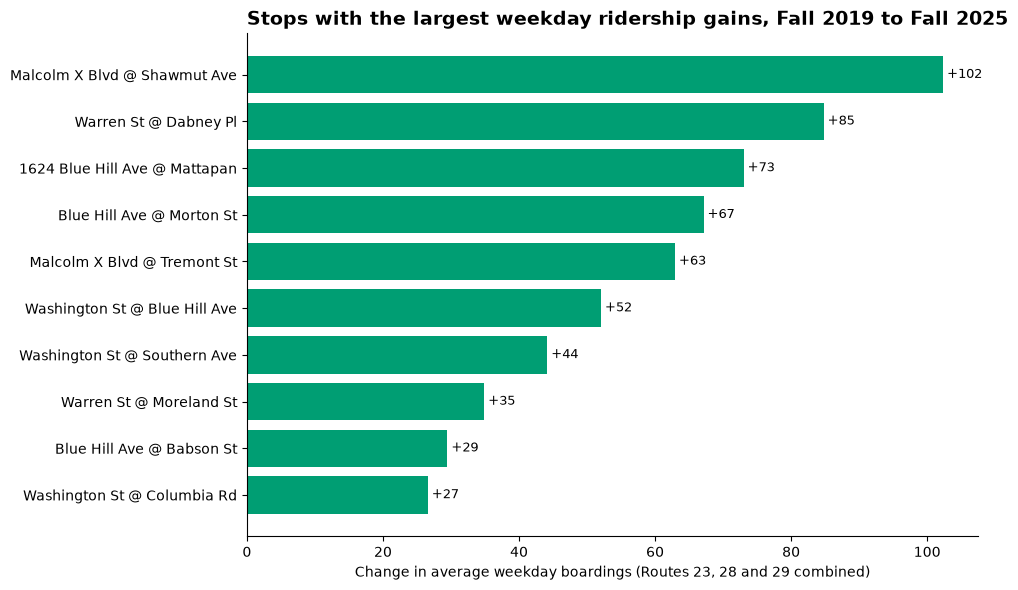

In [50]:
def stop_boardings(year):
    return ff_stops[ff_stops['year'] == year].groupby('stop_id')['boardings'].sum()

stop_change = pd.DataFrame({'y2019': stop_boardings(2019), 'latest': stop_boardings(latest)}).dropna()
stop_change['change'] = stop_change['latest'] - stop_change['y2019']

names = ff_stops.groupby('stop_id')['stop_name'].first()
stop_change['stop_name'] = names.reindex(stop_change.index).str.title()

gainers = stop_change.sort_values('change', ascending=False).head(10).sort_values('change')

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(gainers['stop_name'], gainers['change'], color='#009E73')

for i, value in enumerate(gainers['change']):
    ax.text(value, i, f' {value:+,.0f}', va='center', fontsize=9)

ax.set_title(f'Stops with the largest weekday ridership gains, Fall 2019 to Fall {latest}',
             fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Change in average weekday boardings (Routes 23, 28 and 29 combined)')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(figures + r'\chart7_stop_gains.png', dpi=200, bbox_inches='tight')
plt.show()

In [51]:
service = pd.read_csv(processed + r'\service_route_month.csv', dtype={'route_id': str})
service['group'] = service['route_id'].apply(route_group)

def plot_service_by_year(metric, day_type, period, title, ylabel, file_name, as_percent=False):
    """Yearly line chart of one service measure for the five groups."""
    data = service[(service['day_type'] == day_type) & (service['period'] == period)]

    # Average each route over the year, then average the routes in each group
    route_level = data.groupby(['group', 'route_id', 'year'], as_index=False)[metric].mean()
    group_level = route_level.groupby(['year', 'group'])[metric].mean().unstack('group')[order]
    if as_percent:
        group_level = group_level * 100

    fig, ax = plt.subplots(figsize=(11, 6))
    for col in group_level.columns:
        is_route = 'Route' in col
        ax.plot(group_level.index, group_level[col], marker='o',
                linewidth=2.5 if is_route else 2, linestyle='-' if is_route else '--',
                color=colors[col], label=labels[col])

    ymin, ymax = group_level.min().min(), group_level.max().max()
    pad = (ymax - ymin) * 0.4
    ax.set_ylim(ymin - pad * 0.3, ymax + pad)               # room at the top for labels
    add_program_markers(ax)

    ax.set_title(title, fontsize=14, fontweight='bold', loc='left')
    ax.set_xlabel('Year')
    ax.set_ylabel(ylabel)
    ax.set_xticks(group_level.index)
    ax.set_xlim(2019.4, 2025.6)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False)
    fig.text(0.01, 0.01, 'Source: MBTA Bus Arrival/Departure Times. Yearly average of monthly values.',
             fontsize=8, color='gray')

    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.savefig(figures + '\\' + file_name, dpi=200, bbox_inches='tight')
    plt.show()
    return group_level.round(2)

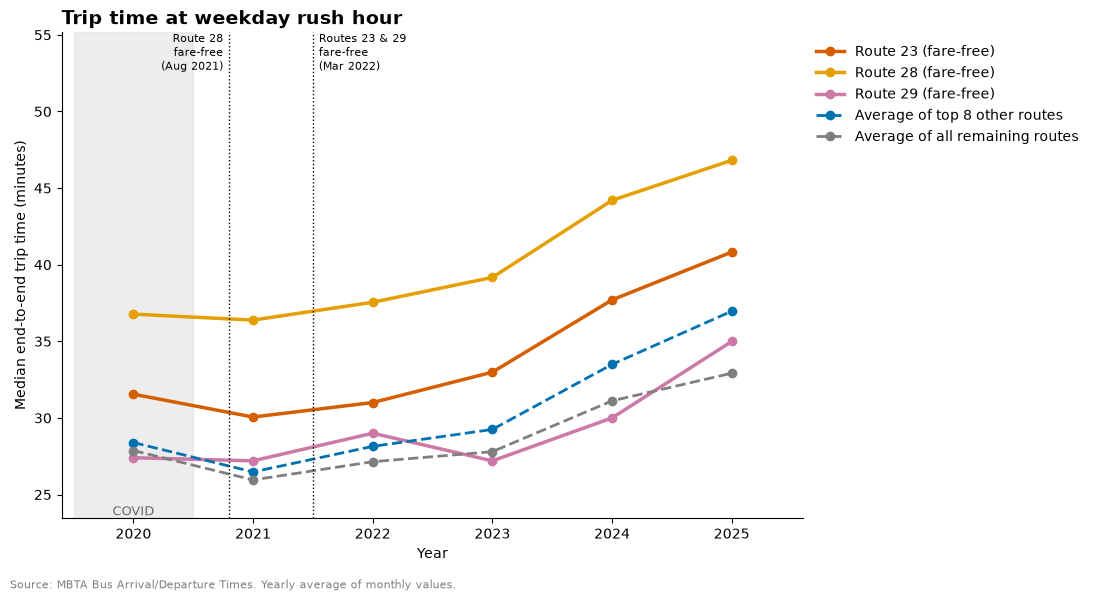

group,Route 23,Route 28,Route 29,Top 8 avg,Rest avg
year,,,,,
2020,31.55,36.78,27.40,28.40,27.87
2021,30.06,36.39,27.20,26.48,25.96
2022,31.01,37.55,29.00,28.15,27.14
2023,32.99,39.17,27.20,29.25,27.80
2024,37.70,44.20,30.00,33.50,31.12
2025,40.82,46.82,34.99,36.97,32.92


In [52]:
plot_service_by_year('median_trip_time_min', 'weekday', 'peak',
                     'Trip time at weekday rush hour', 'Median end-to-end trip time (minutes)',
                     'chart8_trip_time_peak.png')

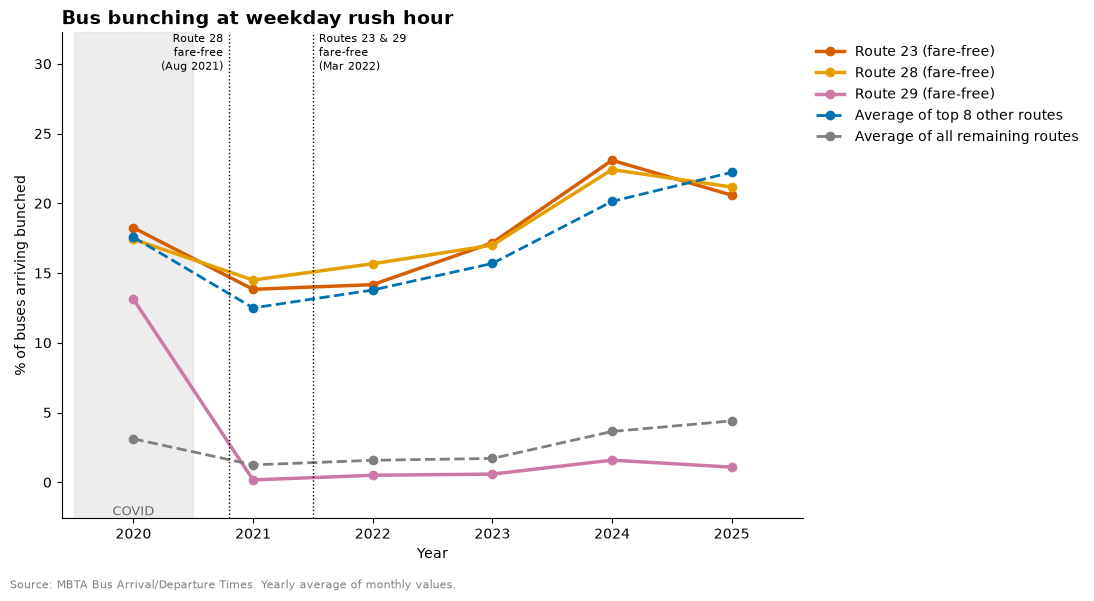

group,Route 23,Route 28,Route 29,Top 8 avg,Rest avg
year,,,,,
2020,18.25,17.42,13.12,17.57,3.11
2021,13.83,14.50,0.17,12.50,1.24
2022,14.17,15.67,0.50,13.78,1.58
2023,17.17,17.00,0.58,15.69,1.71
2024,23.08,22.42,1.58,20.14,3.64
2025,20.58,21.17,1.08,22.22,4.40


In [53]:
plot_service_by_year('pct_bunched', 'weekday', 'peak',
                     'Bus bunching at weekday rush hour', '% of buses arriving bunched',
                     'chart9_bunching_peak.png', as_percent=True)

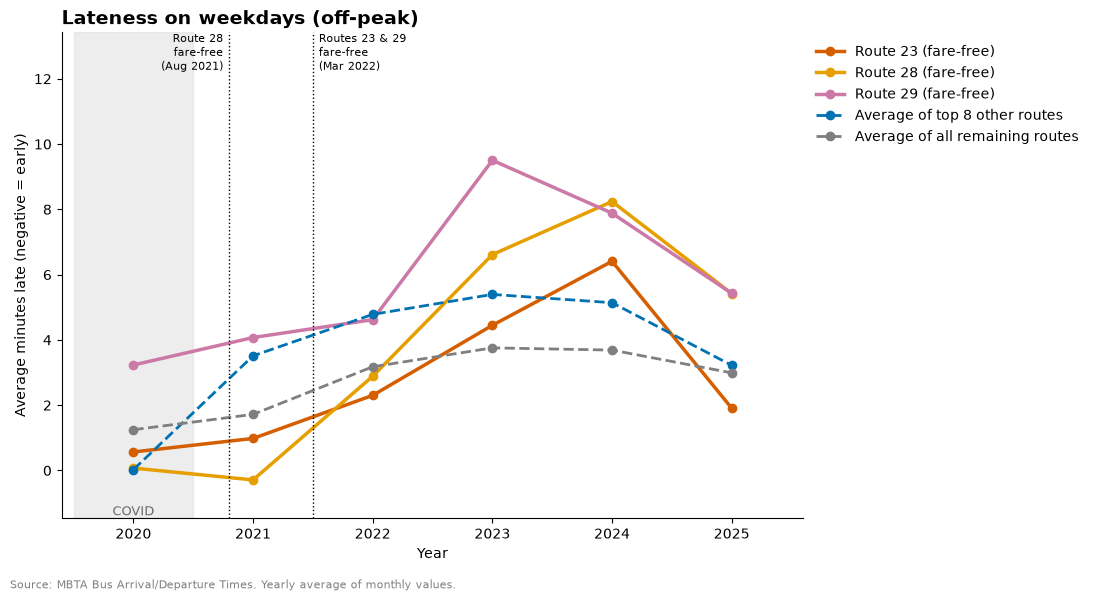

group,Route 23,Route 28,Route 29,Top 8 avg,Rest avg
year,,,,,
2020,0.57,0.07,3.23,0.03,1.25
2021,0.98,-0.29,4.07,3.51,1.72
2022,2.30,2.89,4.62,4.78,3.18
2023,4.45,6.61,9.50,5.39,3.76
2024,6.41,8.24,7.88,5.14,3.69
2025,1.91,5.42,5.43,3.22,2.99


In [54]:
plot_service_by_year('avg_lateness_min', 'weekday', 'off_peak',
                     'Lateness on weekdays (off-peak)', 'Average minutes late (negative = early)',
                     'chart10_lateness.png')

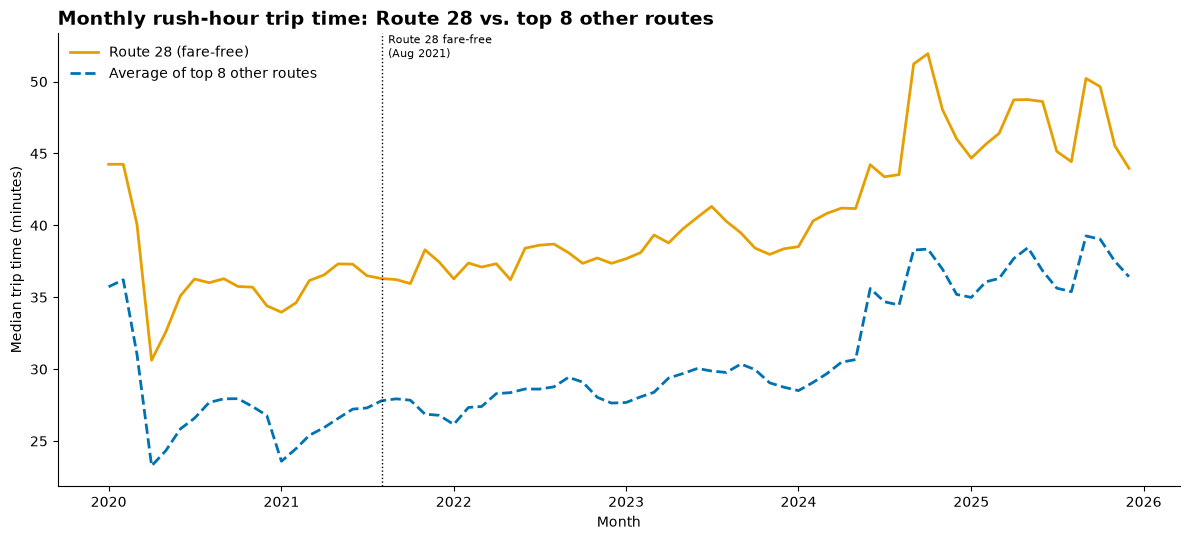

In [55]:
monthly = service[(service['day_type'] == 'weekday') & (service['period'] == 'peak') &
                  ((service['route_id'] == '28') | (service['group'] == 'Top 8 avg'))]
monthly = monthly.groupby(['group', 'year', 'month'], as_index=False)['median_trip_time_min'].mean()
monthly['date'] = pd.to_datetime(monthly['year'].astype(str) + '-' + monthly['month'].astype(str) + '-01')

fig, ax = plt.subplots(figsize=(12, 5.5))
for g in ['Route 28', 'Top 8 avg']:
    d = monthly[monthly['group'] == g].sort_values('date')
    ax.plot(d['date'], d['median_trip_time_min'], linewidth=2, color=colors[g], label=labels[g],
            linestyle='-' if g == 'Route 28' else '--')

ax.axvline(pd.Timestamp('2021-08-01'), color='black', linestyle=':', linewidth=1)
ax.text(pd.Timestamp('2021-08-15'), ax.get_ylim()[1], 'Route 28 fare-free\n(Aug 2021)', va='top', fontsize=8)

ax.set_title('Monthly rush-hour trip time: Route 28 vs. top 8 other routes', fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Month')
ax.set_ylabel('Median trip time (minutes)')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(figures + r'\chart11_monthly_trip_time.png', dpi=200, bbox_inches='tight')
plt.show()

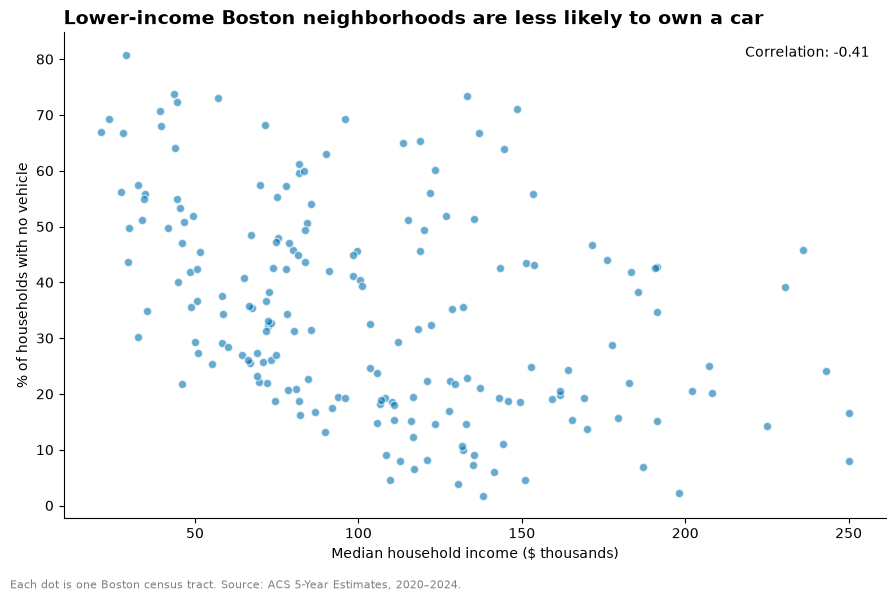

In [56]:
acs = pd.read_csv(processed + r'\acs_2019_2024_combined.csv', dtype={'GEOID': str})
acs24 = acs[acs['year'] == 2024]

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(acs24['median_hh_income'] / 1000, acs24['pct_no_vehicle'] * 100,
           alpha=0.6, color='#0072B2', edgecolor='white')

corr = acs24['median_hh_income'].corr(acs24['pct_no_vehicle'])
ax.text(0.98, 0.95, f'Correlation: {corr:.2f}', transform=ax.transAxes, ha='right', fontsize=10)

ax.set_title('Lower-income Boston neighborhoods are less likely to own a car',
             fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Median household income ($ thousands)')
ax.set_ylabel('% of households with no vehicle')
ax.spines[['top', 'right']].set_visible(False)
fig.text(0.01, 0.01, 'Each dot is one Boston census tract. Source: ACS 5-Year Estimates, 2020–2024.',
         fontsize=8, color='gray')

plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig(figures + r'\chart12_income_vs_car.png', dpi=200, bbox_inches='tight')
plt.show()

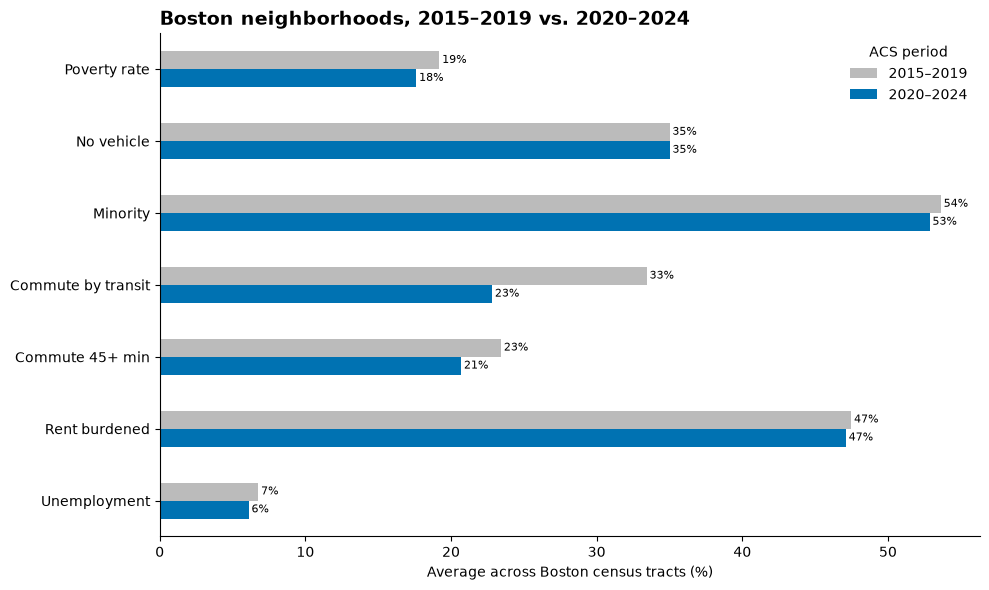

In [57]:
measures = {
    'pct_poverty':       'Poverty rate',
    'pct_no_vehicle':    'No vehicle',
    'pct_minority':      'Minority',
    'pct_transit':       'Commute by transit',
    'pct_long_commute':  'Commute 45+ min',
    'pct_rent_burdened': 'Rent burdened',
    'unemployment_rate': 'Unemployment',
}

acs_change = acs.groupby('year')[list(measures.keys())].mean().T * 100
acs_change.index = [measures[m] for m in acs_change.index]
acs_change.columns = ['2015–2019', '2020–2024']

ax = acs_change.plot(kind='barh', figsize=(10, 6), color=['#bbbbbb', '#0072B2'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', fontsize=8, padding=2)

ax.set_title('Boston neighborhoods, 2015–2019 vs. 2020–2024', fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Average across Boston census tracts (%)')
ax.invert_yaxis()
ax.legend(title='ACS period', frameon=False)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(figures + r'\chart13_acs_change.png', dpi=200, bbox_inches='tight')
plt.show()

In [58]:
route_year[route_year['route_id'] == '29'].pivot(index='year', columns='day_type', values='avg_daily_boardings').round(0)

day_type,saturday,weekday
year,,
2016,478.0,2119.0
2017,458.0,2254.0
2018,433.0,2042.0
2019,394.0,2121.0
2020,183.0,850.0
2021,225.0,1097.0
2022,364.0,1620.0
2023,131.0,1364.0
2024,121.0,1220.0


In [59]:
trips_29 = service[service['route_id'] == '29'].groupby(['year', 'day_type'])['n_trips'].sum().unstack()
trips_29

day_type,saturday,weekday
year,,
2020,803.0,9268.0
2021,923.0,14061.0
2022,1012.0,13792.0
2023,640.0,11551.0
2024,462.0,10091.0
2025,510.0,10128.0


In [60]:
check_trips = service[(service['day_type'] == 'weekday') &
                      (service['group'].isin(['Route 23', 'Route 28', 'Top 8 avg']))]
check_trips.groupby(['year', 'group'])['n_trips'].sum().unstack()

group,Route 23,Route 28,Top 8 avg
year,,,
2020,46256.0,40103.0,384192.0
2021,55394.0,50943.0,483890.0
2022,52697.0,48438.0,443325.0
2023,49689.0,43743.0,416062.0
2024,50892.0,44508.0,426203.0
2025,52095.0,43581.0,428607.0


In [61]:
show = ['Route 23', 'Route 28', 'Route 29', 'Top 8 avg']

# Weekday trips per year (service data)
trips_by_group = (service[(service['day_type'] == 'weekday') & (service['group'].isin(show))]
                  .groupby(['year', 'group'])['n_trips'].sum()
                  .unstack()[show])

# Use 2021-2025 for both (service data starts in 2020, and 2020 trips are undercounted)
trips_by_group  = trips_by_group.loc[2021:2025]
riders_by_group = summary.loc[2021:2025, show]

# % change from 2021
trips_pct  = (trips_by_group / trips_by_group.loc[2021] - 1) * 100
riders_pct = (riders_by_group / riders_by_group.loc[2021] - 1) * 100

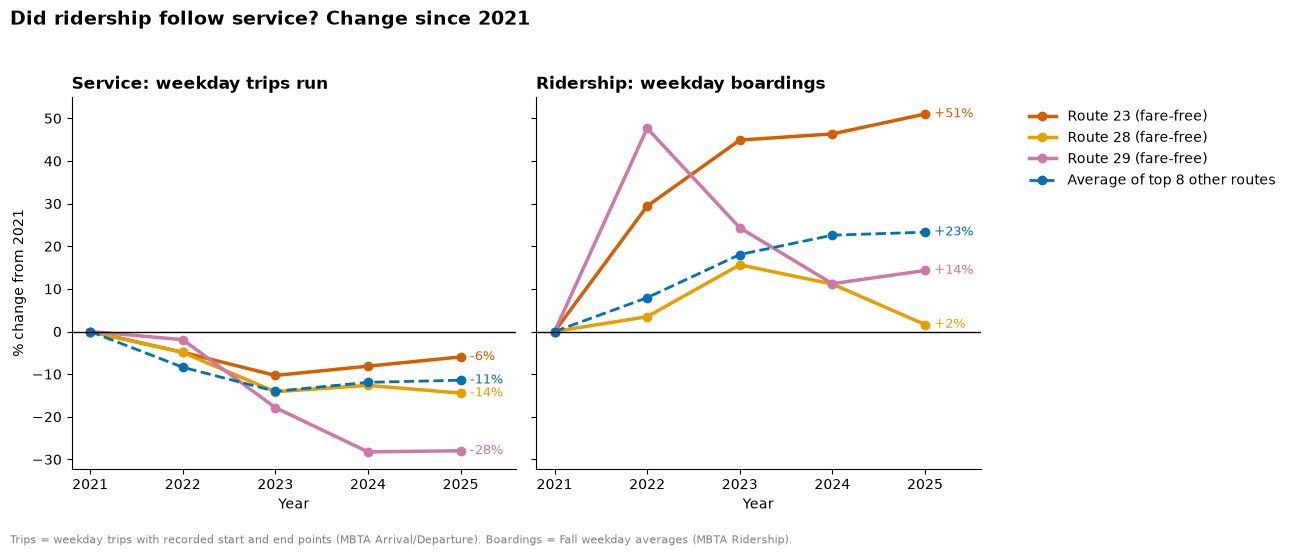

In [62]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)   # same y-axis for both panels

for ax, data, title in [(ax1, trips_pct,  'Service: weekday trips run'),
                        (ax2, riders_pct, 'Ridership: weekday boardings')]:
    for col in show:
        is_route = 'Route' in col
        ax.plot(data.index, data[col], marker='o',
                linewidth=2.5 if is_route else 2, linestyle='-' if is_route else '--',
                color=colors[col], label=labels[col])
        # Label the 2025 value at the end of each line
        ax.text(2025.1, data[col].iloc[-1], f'{data[col].iloc[-1]:+.0f}%',
                va='center', fontsize=9, color=colors[col])

    ax.axhline(0, color='black', linewidth=1)
    ax.set_title(title, fontsize=12, fontweight='bold', loc='left')
    ax.set_xticks(data.index)
    ax.set_xlim(2020.8, 2025.6)
    ax.set_xlabel('Year')
    ax.spines[['top', 'right']].set_visible(False)

ax1.set_ylabel('% change from 2021')
ax2.legend(loc='upper left', bbox_to_anchor=(1.08, 1), frameon=False)

fig.suptitle('Did ridership follow service? Change since 2021', fontsize=14, fontweight='bold', x=0.01, ha='left')
fig.text(0.01, 0.01, 'Trips = weekday trips with recorded start and end points (MBTA Arrival/Departure). '
         'Boardings = Fall weekday averages (MBTA Ridership).', fontsize=8, color='gray')

plt.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.savefig(figures + r'\chart14_service_vs_ridership.png', dpi=200, bbox_inches='tight')
plt.show()

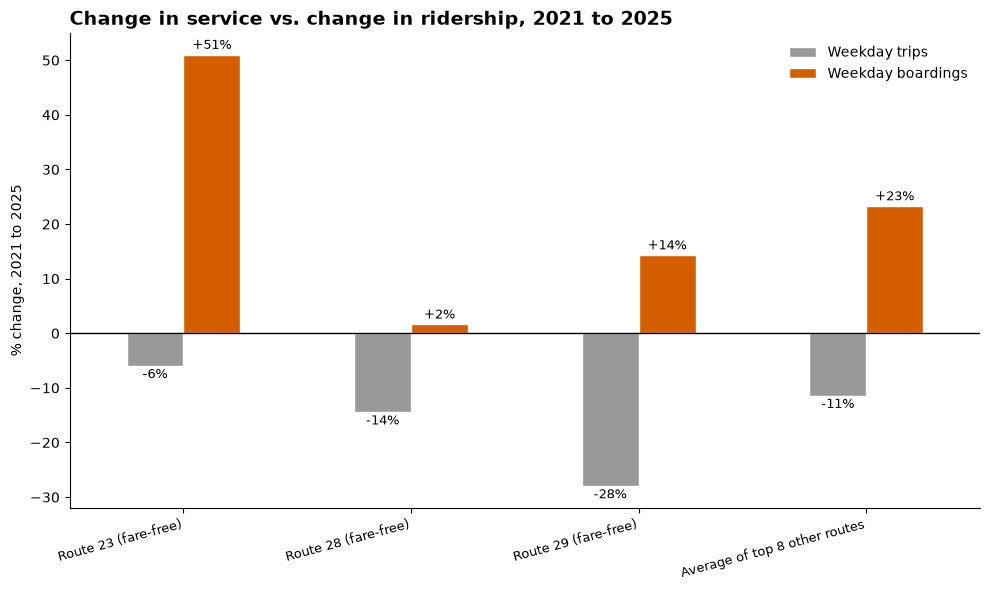

,Weekday trips,Weekday boardings
Route 23 (fare-free),-6.0,51.0
Route 28 (fare-free),-14.5,1.6
Route 29 (fare-free),-28.0,14.3
Average of top 8 other routes,-11.4,23.3


In [63]:
compare = pd.DataFrame({'Weekday trips':     trips_pct.loc[2025],
                        'Weekday boardings': riders_pct.loc[2025]})
compare.index = [labels[g] for g in compare.index]

ax = compare.plot(kind='bar', figsize=(10, 6), color=['#999999', '#D55E00'], edgecolor='white')
for container in ax.containers:
    ax.bar_label(container, fmt='%+.0f%%', fontsize=9, padding=2)    # value on each bar

ax.axhline(0, color='black', linewidth=1)
ax.set_title('Change in service vs. change in ridership, 2021 to 2025', fontsize=14, fontweight='bold', loc='left')
ax.set_ylabel('% change, 2021 to 2025')
ax.set_xlabel('')
plt.setp(ax.get_xticklabels(), rotation=15, ha='right', fontsize=9)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(figures + r'\chart15_service_vs_ridership_bars.png', dpi=200, bbox_inches='tight')
plt.show()

compare.round(1)